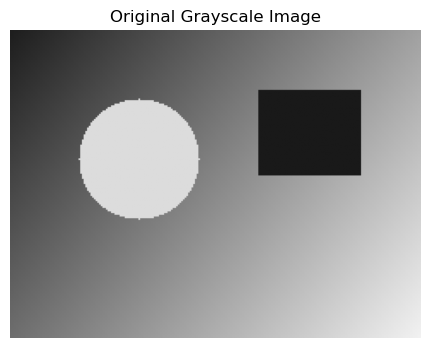

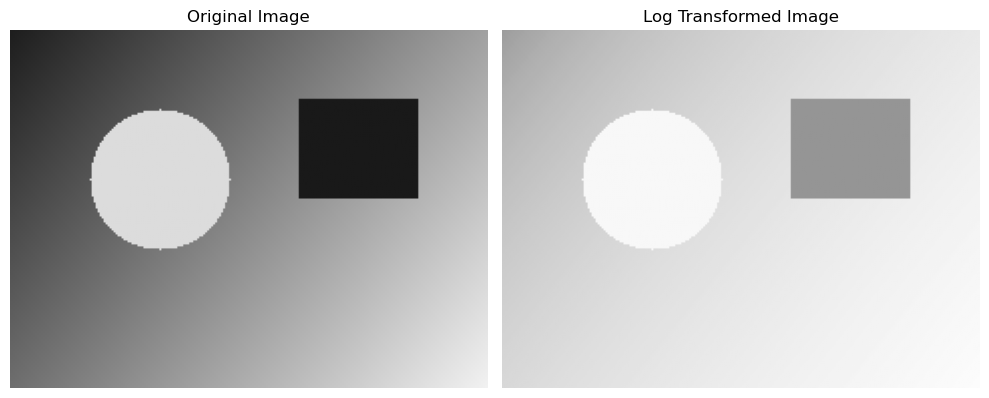

Enter gamma value:  0.6


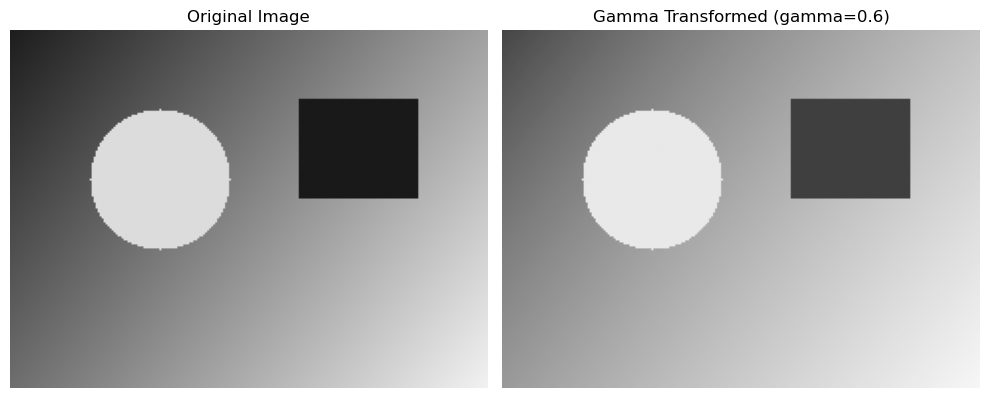

Enter input minimum intensity:  80
Enter input maximum intensity:  180
Enter output minimum intensity:  40
Enter output maximum intensity:  220


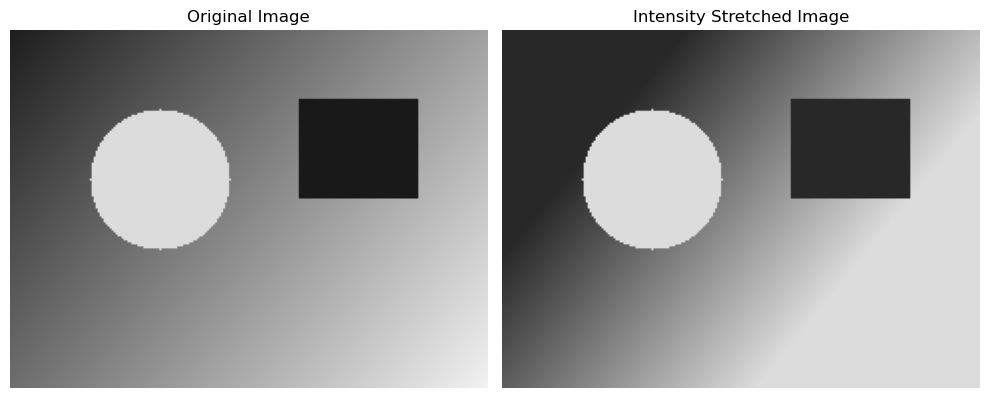

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Generate sample grayscale image
height, width = 180, 240
y, x = np.mgrid[0:height, 0:width]

gray_image = np.clip(30 + 0.55*x + 0.45*y, 0, 255).astype(np.uint8)

yy, xx = np.ogrid[:height, :width]
gray_image[(xx-75)**2 + (yy-75)**2 <= 35**2] = 220
gray_image[35:85, 145:205] = 25

# Display original image
plt.figure(figsize=(6, 4))
plt.imshow(gray_image, cmap='gray', vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis('off')
plt.show()


# ------------------------------------------------
# CASE 1: LOG TRANSFORMATION (c = 1)
# ------------------------------------------------

log_image = np.log1p(gray_image.astype(float))

# Scale output to 0-255 for display
log_image = (
    log_image * 255 / np.log(256)
).clip(0, 255).astype(np.uint8)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap='gray', vmin=0, vmax=255)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(log_image, cmap='gray', vmin=0, vmax=255)
plt.title("Log Transformed Image")
plt.axis('off')

plt.tight_layout()
plt.show()


# ------------------------------------------------
# CASE 2: POWER LAW / GAMMA TRANSFORMATION
# ------------------------------------------------

gamma = float(input("Enter gamma value: "))

if gamma <= 0:
    raise ValueError("Gamma must be greater than zero.")

normalized = gray_image.astype(float) / 255

gamma_image = (
    255 * np.power(normalized, gamma)
).clip(0, 255).astype(np.uint8)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap='gray', vmin=0, vmax=255)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(gamma_image, cmap='gray', vmin=0, vmax=255)
plt.title(f"Gamma Transformed (gamma={gamma})")
plt.axis('off')

plt.tight_layout()
plt.show()


# ------------------------------------------------
# CASE 3: INTENSITY LEVEL SLICING / STRETCHING
# ------------------------------------------------

r1 = int(input("Enter input minimum intensity: "))
r2 = int(input("Enter input maximum intensity: "))

s1 = int(input("Enter output minimum intensity: "))
s2 = int(input("Enter output maximum intensity: "))

if not (0 <= r1 < r2 <= 255):
    raise ValueError("Invalid input intensity range.")

if not (0 <= s1 <= s2 <= 255):
    raise ValueError("Invalid output intensity range.")

# Linear intensity stretching
stretched = s1 + (
    (gray_image.astype(float) - r1)
    * (s2 - s1) / (r2 - r1)
)

stretched = np.clip(stretched, s1, s2).astype(np.uint8)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap='gray', vmin=0, vmax=255)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(stretched, cmap='gray', vmin=0, vmax=255)
plt.title("Intensity Stretched Image")
plt.axis('off')

plt.tight_layout()
plt.show()